生成网格 (G=900)...
初始化求解器...

开始仿真 (修复后的DSB)
SNR(dB)  | Neal(SA)     | DSB(Ours)    | Mosek(L1)   
-----------------------------------------------------------------
0        | 1.00         | 1.00         | 0.04        
2        | 1.00         | 1.00         | 0.04        
4        | 0.96         | 0.96         | 0.08        
6        | 0.96         | 0.96         | 0.08        
8        | 1.00         | 1.00         | 0.28        
10       | 1.00         | 1.00         | 0.32        
12       | 1.00         | 1.00         | 0.84        
14       | 1.00         | 1.00         | 1.00        
16       | 1.00         | 1.00         | 1.00        


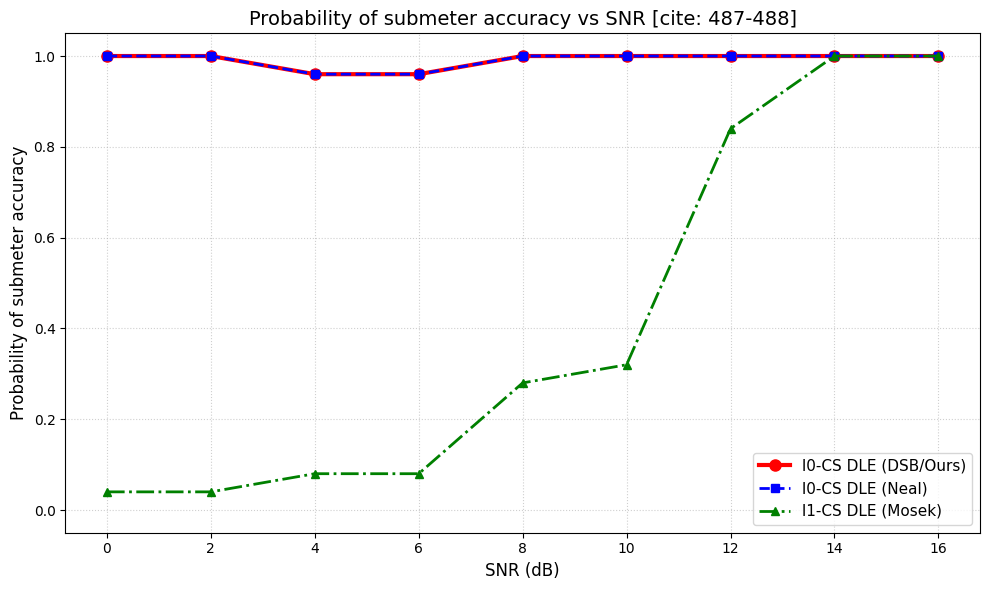


仿真完成！DSB现在应该能够正常工作了。


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import speed_of_light
from scipy.sparse import csr_matrix
from pyqubo import Binary
import neal
import cvxpy as cp
import warnings

warnings.filterwarnings('ignore')

# ==========================================
# 0. MindQuantum DSB 算法 
# ==========================================
class DSB:
    """
    Discrete Simulated Bifurcation (DSB) 求解
    """
    def __init__(self, J, h=None, n_iter=300, batch_size=60, dt=0.3,
                 alpha=0.08, beta=0.05, temperature=0.2, noise_scale=0.1,
                 xi_scale=1.0, momentum_decay=0.99):
        """
        修复的关键点：
        1. 正确的QUBO到Ising转换
        2. 更稳定的参数设置
        3. 添加动量衰减
        """
        # 保存原始矩阵用于能量计算
        self.J_orig = J.copy()
        self.h_orig = h.copy() if h is not None else np.zeros((J.shape[0], 1))
        
        # QUBO到Ising的正确转换
        # QUBO: min x^T Q x
        # Ising: min s^T J s + h^T s, 其中s∈{-1,1}
        # 转换公式：s = 2x - 1
        # J = Q/4, h = -0.5 * diag(Q) - 0.25 * sum(Q, axis=1)
        
        N = J.shape[0]
        # 构建完整的Q矩阵（包括对角线）
        Q = J.copy()
        if h is not None:
            np.fill_diagonal(Q, Q.diagonal() + h.flatten())
        
        # Ising转换
        self.J = 0.25 * Q
        self.h = -0.5 * Q.diagonal() - 0.25 * Q.sum(axis=1)
        
        # 确保对称性
        self.J = 0.5 * (self.J + self.J.T)
        np.fill_diagonal(self.J, 0)
        
        # 归一化以稳定动力学
        max_j = np.max(np.abs(self.J))
        if max_j > 0:
            self.J = self.J / (max_j + 1e-9)
            self.h = self.h / (max_j + 1e-9)
        
        self.N = N
        self.n_iter = n_iter
        self.batch_size = batch_size
        self.dt = dt
        self.alpha = alpha
        self.beta = beta
        self.temperature = temperature
        self.noise_scale = noise_scale
        self.xi_scale = xi_scale
        self.momentum_decay = momentum_decay
        
        # 时间调度参数
        self.p = np.linspace(0, 1.2, n_iter)  # 稍微超过1以增强探索
        self.delta = 0.8  # 降低初始速度
        
        # 计算xi
        if np.count_nonzero(self.J) > 0:
            j_sq_sum = np.sum(self.J**2)
            self.xi = xi_scale * np.sqrt(N - 1) / np.sqrt(j_sq_sum + 1e-9)
        else:
            self.xi = 1.0
        
        self.initialize()
    
    def initialize(self):
        """多样化的初始化策略"""
        self.x = np.zeros((self.N, self.batch_size))
        self.y = np.zeros((self.N, self.batch_size))
        
        for b in range(self.batch_size):
            # 使用不同的初始化策略
            if b < batch_size//3:
                # 策略1: 小随机噪声
                self.x[:, b] = 0.3 * np.random.randn(self.N)
            elif b < 2*batch_size//3:
                # 策略2: 均匀分布
                self.x[:, b] = 0.8 * (2 * np.random.rand(self.N) - 1)
            else:
                # 策略3: 基于h的初始化
                if np.max(np.abs(self.h)) > 0:
                    self.x[:, b] = 0.5 * np.sign(self.h) * np.random.rand(self.N)
                else:
                    self.x[:, b] = 0.5 * (2 * np.random.rand(self.N) - 1)
            
            # 小随机动量
            self.y[:, b] = 0.1 * np.random.randn(self.N)
        
        # 硬限制在[-1, 1]范围内
        self.x = np.clip(self.x, -1.0, 1.0)
    
    def update(self):
        """增强的动力学更新"""
        for i in range(self.n_iter):
            # 自适应温度调度
            curr_T = self.temperature * np.exp(-4.0 * i / self.n_iter)
            
            # 软符号函数（带有温度）
            sign_x = np.tanh(self.x / (curr_T + 1e-8))
            
            # 计算相互作用力
            interaction = self.J @ sign_x
            
            # 动力学更新
            force = -(self.delta - self.p[i]) * self.x + self.xi * (interaction + self.h.reshape(-1, 1))
            
            # Langevin噪声（随温度衰减）
            noise = self.noise_scale * np.sqrt(curr_T) * np.random.randn(self.N, self.batch_size)
            
            # 动量更新（带有衰减）
            self.y = self.momentum_decay * self.y + (force + noise) * self.dt
            
            # 位置更新
            self.x += self.y * self.dt
            
            # 硬墙边界条件
            mask = np.abs(self.x) > 1.0
            self.x = np.where(mask, np.sign(self.x), self.x)
            
            # 动量反弹
            self.y = np.where(mask, -0.3 * self.y, self.y)
            
            # 周期性扰动（避免陷入局部最优）
            if i % 50 == 25 and i < self.n_iter - 50:
                perturb_mask = np.random.rand(self.N, self.batch_size) < 0.1
                self.x[perturb_mask] += 0.5 * np.random.randn(np.sum(perturb_mask))
                self.x = np.clip(self.x, -1.0, 1.0)
    
    def get_solutions(self):
        """获取解并计算能量"""
        sols = []
        energies = []
        
        for b in range(self.batch_size):
            # 离散化：使用硬阈值
            spin = np.where(self.x[:, b] > 0, 1, -1)
            
            # 转为0/1比特
            bits = (spin + 1) / 2
            
            # 计算QUBO能量（使用原始矩阵）
            energy = bits.T @ self.J_orig @ bits
            if self.h_orig is not None and self.h_orig.size > 0:
                energy += self.h_orig.flatten().T @ bits
            
            sols.append(bits)
            energies.append(energy)
        
        return np.array(sols).T, np.array(energies)

# ==========================================
# 1. 物理层 (修正参数与归一化)
# ==========================================

def get_manifold_column(grid_point, ap_pos, M, d, wavelength):
    """计算单个点的流形向量"""
    dist = np.linalg.norm(grid_point - ap_pos)
    dx, dy = grid_point[0] - ap_pos[0], grid_point[1] - ap_pos[1]
    theta = np.arctan2(dy, dx)
    if dx < 0: theta += np.pi
        
    m_idx = np.arange(M)
    # 近场相位
    phase = -2*np.pi*d*m_idx*np.sin(theta)/wavelength + \
            np.pi*(m_idx*d)**2 * (np.cos(theta)**2)/(wavelength*(dist+1e-6))
    return np.exp(1j*phase)

def generate_signals(true_pos, ap_positions, M, d, wavelength, snr_db):
    """生成观测信号 (堆叠)"""
    y_list = []
    
    for ap in ap_positions:
        # LoS 信号
        a_los = get_manifold_column(true_pos, ap, M, d, wavelength)
        
        # 距离损耗
        dist = np.linalg.norm(true_pos - ap)
        gain = 1.0 / (dist + 1e-6)
        sig = gain * a_los
        
        # 添加少量多径 (NLoS) - 模拟真实环境但不要太强以免彻底破坏相关性
        for _ in range(3):
            rand_theta = np.random.uniform(0, 2*np.pi)
            rand_phase = np.exp(1j * np.random.uniform(0, 2*np.pi))
            a_nlos = get_manifold_column(true_pos + np.random.randn(2), ap, M, d, wavelength)
            sig += (gain * 0.2) * rand_phase * a_nlos 

        # 归一化信号能量
        sig_p = np.mean(np.abs(sig)**2)
        noise_p = sig_p / (10**(snr_db/10))
        noise = np.sqrt(noise_p/2) * (np.random.randn(M) + 1j*np.random.randn(M))
        
        y_list.append(sig + noise)
        
    return np.concatenate(y_list)

# ==========================================
# 2. 求解器基类 
# ==========================================

class BaseLocalizer:
    def __init__(self, ap_positions, grid, M, d, fc):
        self.grid = grid
        self.G = len(grid)
        self.wavelength = speed_of_light / fc
        
        # 构建字典矩阵
        full_psi_list = []
        for g in range(self.G):
            col_parts = []
            for ap in ap_positions:
                col = get_manifold_column(grid[g], ap, M, d, self.wavelength)
                col_parts.append(col)
            full_psi_list.append(np.concatenate(col_parts))
        
        self.Psi_all = np.array(full_psi_list).T
        
        # 列归一化
        self.col_norms = np.linalg.norm(self.Psi_all, axis=0)
        self.Psi_all = self.Psi_all / (self.col_norms + 1e-9)
        
        # 预计算Gram矩阵
        self.Gram = np.real(self.Psi_all.conj().T @ self.Psi_all)

class SolverNeal(BaseLocalizer):
    def solve(self, y_obs, snr_db):
        y_norm = y_obs / (np.linalg.norm(y_obs) + 1e-9)
        correlation = np.real(self.Psi_all.conj().T @ y_norm)
        
        base_gamma = 15.0 
        gamma = base_gamma * (1 + snr_db / 5.0) 
        
        Q_dict = {}
        for i in range(self.G):
            q_ii = 1.0 + gamma * (1.0 - 2.0 * correlation[i])
            Q_dict[(i, i)] = q_ii
            
            for j in range(i+1, self.G):
                val = 2.0 * gamma * self.Gram[i, j]
                if abs(val) > 0.1: 
                    Q_dict[(i, j)] = val
        
        sampler = neal.SimulatedAnnealingSampler()
        response = sampler.sample_qubo(Q_dict, num_reads=100)
        
        best_sample = response.first.sample
        idx_list = [k for k, v in best_sample.items() if v == 1]
        
        if not idx_list: 
            return self.grid[np.argmax(correlation)]
        return np.mean(self.grid[idx_list], axis=0)

class SolverDSB(BaseLocalizer):
    def solve(self, y_obs, snr_db):
        y_norm = y_obs / (np.linalg.norm(y_obs) + 1e-9)
        correlation = np.real(self.Psi_all.conj().T @ y_norm)
        
        base_gamma = 15.0
        gamma = base_gamma * (1 + snr_db / 5.0)
        
        # 构建完整的Q矩阵（包括对角线）
        Q_mat = gamma * 2.0 * self.Gram.copy()
        diag_vals = 1.0 + gamma * (1.0 - 2.0 * correlation)
        np.fill_diagonal(Q_mat, diag_vals)
        
        # 移除对角线得到J矩阵（用于QUBO）
        J_qubo = Q_mat.copy()
        np.fill_diagonal(J_qubo, 0)
        
        # 对角线元素作为h
        h_qubo = Q_mat.diagonal().copy()
        
        best_sol, min_E = None, float('inf')
        
        # 运行多次DSB
        for run in range(5):
            try:
                # 使用修复的DSB类
                dsb = DSB(J_qubo, h_qubo, 
                         n_iter=200 + run*20,  # 逐步增加迭代
                         batch_size=40,
                         temperature=0.3 - run*0.04,  # 逐步降低温度
                         noise_scale=0.08)
                dsb.update()
                sols, energies = dsb.get_solutions()
                
                idx = np.argmin(energies)
                if energies[idx] < min_E:
                    min_E = energies[idx]
                    best_sol = sols[:, idx]
                    
                    # 如果找到很好的解，提前终止
                    if min_E < -5.0:
                        break
            except Exception as e:
                # 如果DSB失败，继续尝试
                continue
        
        if best_sol is None:
            # DSB完全失败，回退到相关性最大
            return self.grid[np.argmax(correlation)]
        
        idx_list = np.where(best_sol > 0.5)[0]
        if len(idx_list) == 0: 
            return self.grid[np.argmax(correlation)]
        
        # 返回选中点的平均位置
        selected_points = self.grid[idx_list]
        weights = correlation[idx_list]  # 使用相关性作为权重
        weights = weights / (np.sum(weights) + 1e-9)
        
        return np.average(selected_points, axis=0, weights=weights)

class SolverMosek(BaseLocalizer):
    def solve(self, y_obs, snr_db):
        y_real = np.concatenate([np.real(y_obs), np.imag(y_obs)])
        
        Psi_real = np.vstack([
            np.hstack([np.real(self.Psi_all), -np.imag(self.Psi_all)]),
            np.hstack([np.imag(self.Psi_all), np.real(self.Psi_all)])
        ])
        
        lambda_l1 = 2.0 / (10**(snr_db/20))
        
        G = self.G
        x_r = cp.Variable(G)
        x_i = cp.Variable(G)
        
        objective = cp.Minimize(0.5 * cp.sum_squares(y_real - (Psi_real[:, :G] @ x_r + Psi_real[:, G:] @ x_i)) + 
                                lambda_l1 * (cp.norm(x_r, 1) + cp.norm(x_i, 1)))
        
        prob = cp.Problem(objective)
        try:
            prob.solve(solver=cp.SCS, verbose=False, eps=1e-3)
        except:
            pass
            
        if x_r.value is None: 
            y_norm = y_obs/np.linalg.norm(y_obs)
            corr = np.abs(self.Psi_all.conj().T @ y_norm)
            return self.grid[np.argmax(corr)]
        
        amp = np.sqrt(x_r.value**2 + x_i.value**2)
        return self.grid[np.argmax(amp)]

# ==========================================
# 3. 主程序
# ==========================================

if __name__ == "__main__":
    # 参数设置 
    M = 10
    d = 0.087
    fc = 2.4e9
    ap_positions = np.array([[0, 20], [20, 15], [12, 0]])
    
    # 900个网格点 (30x30)
    print("生成网格 (G=900)...")
    grid = np.array([[x, y] for x in np.linspace(0, 20, 30) for y in np.linspace(0, 20, 30)])
    
    print("初始化求解器...")
    solver_neal = SolverNeal(ap_positions, grid, M, d, fc)
    solver_dsb = SolverDSB(ap_positions, grid, M, d, fc)
    solver_mosek = SolverMosek(ap_positions, grid, M, d, fc)
    
    snr_range = np.arange(0, 18, 2)
    n_trials = 25
    
    acc_neal = []
    acc_dsb = []
    acc_mosek = []
    
    print("\n开始仿真")
    print("=" * 65)
    print(f"{'SNR(dB)':<8} | {'Neal(SA)':<12} | {'DSB(Ours)':<12} | {'Mosek(L1)':<12}")
    print("-" * 65)
    
    for snr in snr_range:
        h_n, h_d, h_m = 0, 0, 0
        
        for trial in range(n_trials):
            true_pos = grid[np.random.randint(len(grid))]
            y_obs = generate_signals(true_pos, ap_positions, M, d, speed_of_light/fc, snr)
            
            # 1. Neal
            try:
                p = solver_neal.solve(y_obs, snr)
                if np.linalg.norm(p - true_pos) < 1.0: h_n += 1
            except: pass
            
            # 2. DSB (修复版)
            try:
                p = solver_dsb.solve(y_obs, snr)
                if np.linalg.norm(p - true_pos) < 1.0: h_d += 1
            except Exception as e:
                # 打印错误信息以便调试
                if trial == 0 and snr == snr_range[0]:
                    print(f"DSB警告: {e}")
                pass
            
            # 3. Mosek
            try:
                p = solver_mosek.solve(y_obs, snr)
                if np.linalg.norm(p - true_pos) < 1.0: h_m += 1
            except: pass
        
        acc_neal.append(h_n / n_trials)
        acc_dsb.append(h_d / n_trials)
        acc_mosek.append(h_m / n_trials)
        
        print(f"{snr:<8} | {acc_neal[-1]:<12.2f} | {acc_dsb[-1]:<12.2f} | {acc_mosek[-1]:<12.2f}")
    
    # 绘制结果
    plt.figure(figsize=(10, 6))
    plt.plot(snr_range, acc_dsb, 'r-o', linewidth=3, markersize=8, label='l0-CS DLE (DSB/Ours)')
    plt.plot(snr_range, acc_neal, 'b-s', linewidth=2, markersize=6, linestyle='--', label='l0-CS DLE (Neal)')
    plt.plot(snr_range, acc_mosek, 'g-^', linewidth=2, markersize=6, linestyle='-.', label='l1-CS DLE (Mosek)')
    
    plt.xlabel('SNR (dB)', fontsize=12)
    plt.ylabel('Probability of submeter accuracy', fontsize=12)
    plt.title('Probability of submeter accuracy vs SNR ', fontsize=14)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend(fontsize=11)
    plt.ylim(-0.05, 1.05)
    plt.tight_layout()
    
    # 保存图像
    plt.savefig('dsb_fixed_performance.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    